In [239]:
'general useful packages'

import numpy as np
import matplotlib.pyplot as plt
import scipy
import inspect
import math
import pandas as pd
%matplotlib inline

In [240]:
'plot font settings'

plt.rcParams['font.family'] = 'serif'
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.titlesize': 14
})

In [241]:
'Problem 1a'

w_i = np.array([0.13, 0.51, 0.31, 0.37, 0.06, 0.29, 0.28, 0.54, 0.14, 0.30,
0.01, 0.27, 0.18, 0.15, -0.06, 0.44, 0.36, 0.19, 0.34, 0.21,
0.09, 0.59, 0.60, 0.43, 0.35, 0.35, 0.44, 0.40, 0.38, 0.33]) #in mas
n = 30
sigma = 0.15 #in mas

w_avg = np.mean(w_i)
recip_w_avg = 1 / w_avg
one_star_uncertainty = sigma / np.sqrt(n)

print(r"Average paralax:", f"{w_avg:.3f}", "mas", "Average distance:", f"{recip_w_avg:.3f}", "kpc", 
      "Parallax uncertainty:", f"{one_star_uncertainty:.4f}", "mas")


Average paralax: 0.299 mas Average distance: 3.341 kpc Parallax uncertainty: 0.0274 mas


In [242]:
'Problem 1b'

distance = 1/w_i
avg_distance = np.mean(distance)
print(r"Average distance:", f"{avg_distance:.3f}", "kpc")

'should average first because those small outliers blow up when taking the reciprocal, leading to an erroneous distance calculation'

Average distance: 6.727 kpc


'should average first because those small outliers blow up when taking the reciprocal, leading to an erroneous distance calculation'

In [243]:
'Problem 1c'

w_i = np.array([0.13, 0.51, 0.31, 0.37, 0.06, 0.29, 0.28, 0.54, 0.14, 0.30,
0.01, 0.27, 0.18, 0.15, -0.06, 0.44, 0.36, 0.19, 0.34, 0.21,
0.09, 0.59, 0.60, 0.43, 0.35, 0.35, 0.44, 0.40, 0.38, 0.33]) #in mas
n = 30
sigma = 0.15 #in mas
sigma_delta = 0.02 #in mas

def ln_prob(w_i, w_c, delta):
    if not (0 < w_c < np.inf): #flat prior
        return -np.inf
    return -((1/(2 * sigma**2)) * np.sum((w_i - w_c- delta)**2)) - (1/(2 * sigma_delta**2)) * delta**2

n_steps = 20000
p0 = np.array([0.3, 0.0])
samples = np.zeros((n_steps, 2))

for i in range(n_steps):

    proposal = p0 + np.random.normal(0, 0.04, size=2)
    ln_current = ln_prob(w_i, p0[0], p0[1])
    ln_proposal = ln_prob(w_i, proposal[0], proposal[1])
    alpha = ln_proposal - ln_current

    #Metropolis acceptance rules
    if alpha >= 0:
        p0 = proposal
    else:
        u = np.random.uniform(0, 1)
        if u < np.exp(alpha):
            p0 = proposal
        else:
            p0 = p0

    samples[i] = p0

samples = samples[1000:]

w_c_samples = samples[:, 0]

r_samples = 1 / w_c_samples

percentiles = np.percentile(r_samples, [16, 50, 84])
onesix_percentile = percentiles[0]
median = percentiles[1]
eightfour_percentile = percentiles[2]

print(f"16th percentile: {onesix_percentile:.3f} kpc, Median: {median:.3f} kpc, 84th percentile: {eightfour_percentile:.3f} kpc")

16th percentile: 3.009 kpc, Median: 3.345 kpc, 84th percentile: 3.764 kpc


b measurements: [0.99780392 0.99813187 1.00162722 ... 0.99872134 1.00209188 0.99753544]
Number of b measurements: 4096
Corresponding period of largest frequency peak in the full spectrum: 3.160 days
Corresponding period of largest frequency peak in the sparse spectrum: 3.185 days
Corresponding period of second largest peak in the full spectrum: 0.551 days
Corresponding period of second largest peak in the sparse spectrum: 5.375 days


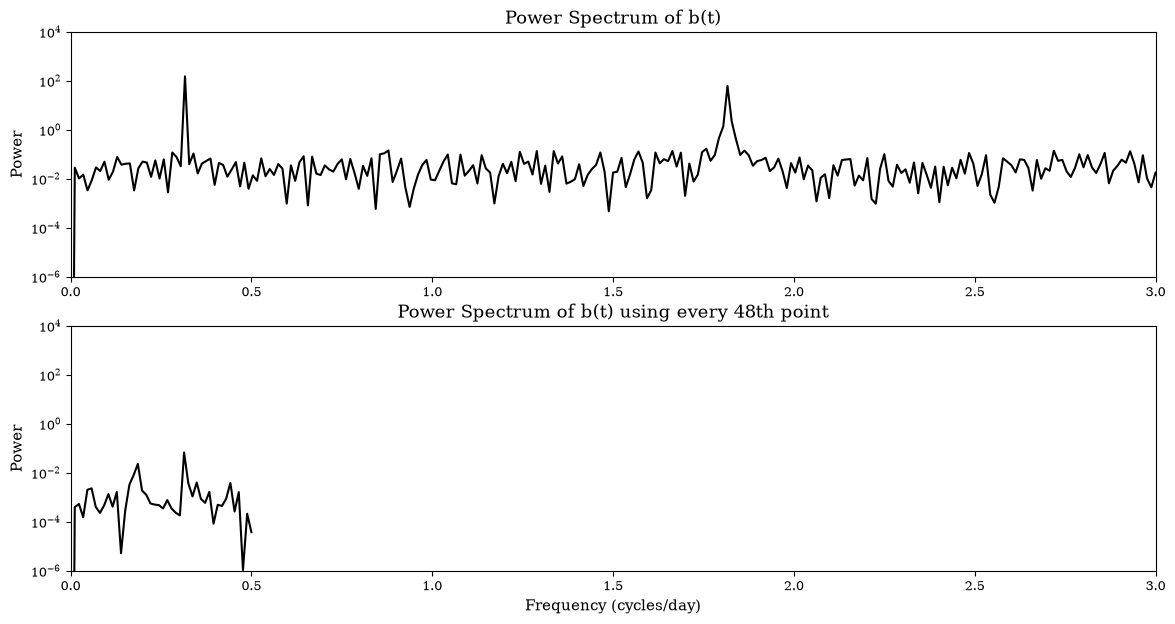

In [244]:
'Problem 2c'

'getting b(t) values'
half_hour = 1 / 48
def b(t):
    noise = np.random.default_rng().normal(loc=0, scale=0.003, size=None)
    return 1 + 0.006 * np.sin(2 * np.pi * t / 3.16) + 0.004 * np.sin(2 * np.pi * t / 0.55) + noise

time = np.linspace(0, 4096/48, 4096, endpoint=False)

b_values = np.array([])
for i in time:
    b_values = np.append(b_values, b(i))

print("b measurements:", b_values)
print("Number of b measurements:", len(b_values))

Nn = 4096

H_k_values = np.fft.rfft(b_values - np.mean(b_values))
power_spectrum = np.abs(H_k_values)**2
frequencies = np.fft.rfftfreq(Nn, d=1/48)

# plt.figure(figsize=(10, 4))
# plt.plot(frequencies, power_spectrum, color = 'black')
# plt.yscale('log')
# plt.xlim(0,3)
# plt.ylim(10**-5, 10**4)
# plt.xlabel("Frequency (cycles/day)")
# plt.ylabel("Log(power)")
# plt.title("Power Spectrum of b(t)")

'keeping only every 48th point'

b_sparse = b_values[::48]
H_k_values_sparse = np.fft.rfft(b_sparse - np.mean(b_sparse))
power_spectrum_sparse = np.abs(H_k_values_sparse) ** 2
frequencies_sparse = np.fft.rfftfreq(len(b_sparse), 1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7))

ax1.plot(frequencies, power_spectrum, color='black')
ax1.set_yscale('log')
ax1.set_xlim(0, 3)
ax1.set_ylim(10**-6, 10**4)
ax1.set_ylabel('Power')
ax1.set_title('Power Spectrum of b(t)')

ax2.plot(frequencies_sparse, power_spectrum_sparse, color='black')
ax2.set_yscale('log')
ax2.set_xlim(0, 3)
ax2.set_ylim(10**-6, 10**4)
ax2.set_xlabel('Frequency (cycles/day)')
ax2.set_ylabel('Power')
ax2.set_title('Power Spectrum of b(t) using every 48th point')

print(f"Corresponding period of largest frequency peak in the full spectrum: {1/frequencies[np.argmax(power_spectrum)]:.3f} days")
print(f"Corresponding period of largest frequency peak in the sparse spectrum: {1/frequencies_sparse[np.argmax(power_spectrum_sparse)]:.3f} days")
print(f"Corresponding period of second largest peak in the full spectrum: {1/frequencies[np.argsort(power_spectrum)[-2]]:.3f} days")
print(f"Corresponding period of second largest peak in the sparse spectrum: {1/frequencies_sparse[np.argsort(power_spectrum_sparse)[-2]]:.3f} days")


b measurements: [1.00461558 1.00269417 1.00500997 ... 0.9990683  0.99633432 0.99781402]
Number of b measurements: 4096


Text(0.5, 1.0, 'Power Spectrum of b(t)')

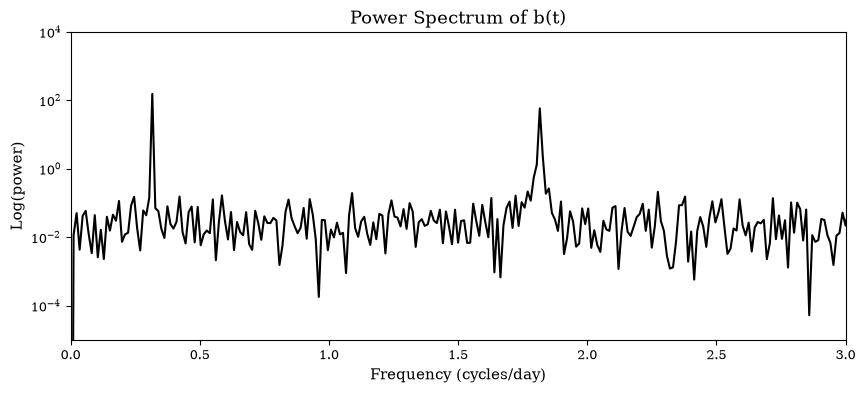

In [245]:
'Problem 2c without using FFT (not my answer to 2c, but a different approach I thought was neat)'

'getting b(t) values'
half_hour = 1 / 48
def b(t):
    noise = np.random.default_rng().normal(loc=0, scale=0.003, size=None)
    return 1 + 0.006 * np.sin(2 * np.pi * t / 3.16) + 0.004 * np.sin(2 * np.pi * t / 0.55) + noise

time = np.linspace(0, 4096/48, 4096, endpoint=False)

b_values = np.array([])
for i in time:
    b_values = np.append(b_values, b(i))

print("b measurements:", b_values)
print("Number of b measurements:", len(b_values))

'finding the power spectrum of b(t)'

Nn = 4096
n = np.arange(Nn)
k = np.linspace(-Nn/2, Nn/2, Nn, endpoint=False)
def H_k(b, n, k):
    return np.sum(b*np.exp(1j * 2 * np.pi * k * n / Nn))


H_k_values = np.array([], dtype=complex)

for i in k:
    H_value = H_k(b_values - np.mean(b_values), n, i)
    H_k_values = np.append(H_k_values, H_value)

power_spectrum = np.abs(H_k_values) ** 2

frequencies = k * 48 / Nn

plt.figure(figsize=(10, 4))
plt.plot(frequencies, power_spectrum, color = 'black')
plt.yscale('log')
plt.xlim(0, 3)
plt.ylim(10**-5, 10**4)
plt.xlabel('Frequency (cycles/day)')
plt.ylabel('Log(power)')
plt.title('Power Spectrum of b(t)')

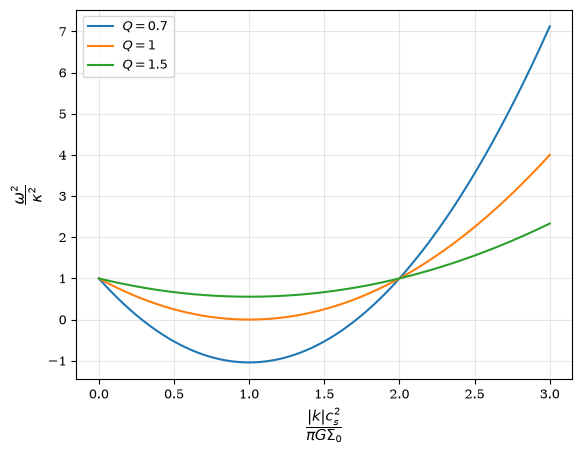

In [246]:
'Problem 3c'

q = (0.7, 1, 1.5)

def y(x):
    return 1 - (2*x/q[i]**2) + (x**2/q[i]**2)

for i in range(len(q)):
    x = np.linspace(0, 3, 1000)
    plt.plot(x, y(x), label=fr'$Q = {q[i]}$')

plt.xlabel(r'$\frac{|k|c_s^2}{\pi G\Sigma_0}$', fontsize=15)
plt.ylabel(r'$\frac{\omega^2}{\kappa^2}$', fontsize=15)
plt.legend()
plt.grid(alpha=0.3)
plt.show()